# Developing a Tiny Transformer Language Model
**PUSL 3205 – Large Language Models and Generative AI | Lab 3**

A GPT-style, decoder-only Transformer built from scratch in PyTorch and trained on the TinyStories dataset for next-token prediction.

In [145]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available: ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

PyTorch version: 2.15.0+cu132
CUDA available:  True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.4 GB
Using device: cuda


## Task 1: Load and Explore the Dataset
**TinyStories** (Eldan & Li, 2023) is a dataset of ~2.1 million short stories written by GPT-3.5/GPT-4 using only words a 3–4-year-old would understand. Its simple vocabulary and grammar make it possible for very small language models to learn to write coherent English.

The full training set is ~2 GB, so we **stream** it and take only the first stories we need, instead of downloading everything.

In [146]:
import random
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [147]:
N_TRAIN_STORIES = 20_000

# Stream the training split and take the first N stories (avoids a ~2 GB download)
train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
train_stories = [ex["text"] for ex in train_stream.take(N_TRAIN_STORIES)]

# The validation split is small, so download it normally
val_ds = load_dataset("roneneldan/TinyStories", split="validation")
val_stories = list(val_ds["text"])

print(f"Training stories loaded:   {len(train_stories):,}")
print(f"Validation stories loaded: {len(val_stories):,}")

Training stories loaded:   20,000
Validation stories loaded: 21,990


### Sample stories

In [148]:
for i in random.sample(range(len(train_stories)), 3):
    print(f"--- Story {i} ---")
    print(train_stories[i])
    print()

--- Story 3648 ---
Jane and Bob were playing in the park. Jane wanted to hold the pretty bull that was walking around. But Bob said it was too big and he thought it might hurt them. So, instead, he offered to show Jane his reliable pet cat. 

Bob told Jane to be gentle and he showed her how to hold the cat. She was scared at first, but after Bob showed her what to do, she gently held the cat and loved it. The cat purred loudly, so Jane knew he liked it too. 

Afterwards, Jane hugged Bob for showing her a reliable and gentle pet that she could hold. Then Bob laughed, and they ran to the playground to play some more.

--- Story 819 ---
Once upon a time, there was a little girl named Lily. She loved to play outside near the river. One day, Lily saw a big raft floating down the river. It looked so fun to play on! 

But Lily didn't have a raft of her own. She asked her friend if she could borrow their raft. Her friend said yes and Lily was so happy! 

Lily got on the raft and it was very co

### Text length

Characters per story: mean=895, median=785, min=205, max=4540
Words per story:      mean=175, median=152, min=43, max=878

Total characters in training subset: 17,890,906


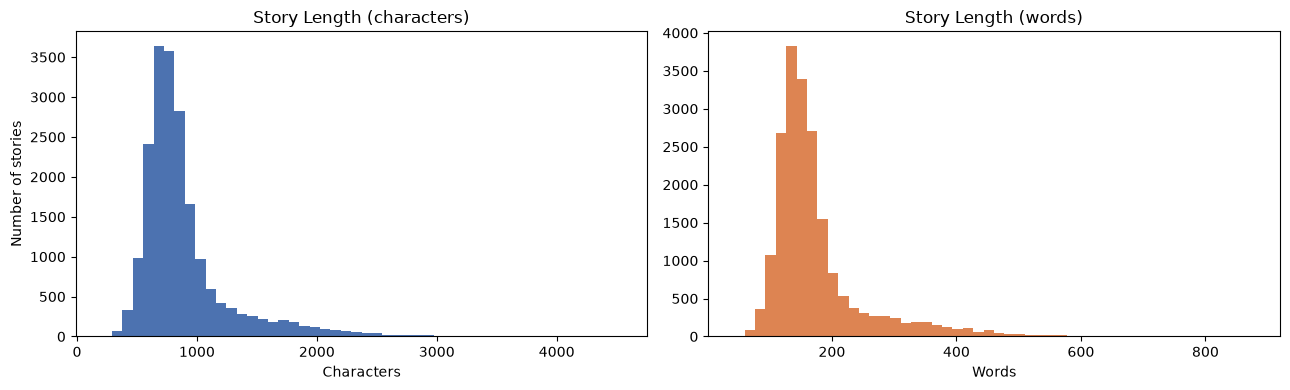

In [149]:
char_lengths = np.array([len(s) for s in train_stories])
word_lengths = np.array([len(s.split()) for s in train_stories])

print(f"Characters per story: mean={char_lengths.mean():.0f}, "
      f"median={np.median(char_lengths):.0f}, "
      f"min={char_lengths.min()}, max={char_lengths.max()}")
print(f"Words per story:      mean={word_lengths.mean():.0f}, "
      f"median={np.median(word_lengths):.0f}, "
      f"min={word_lengths.min()}, max={word_lengths.max()}")
print(f"\nTotal characters in training subset: {char_lengths.sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(char_lengths, bins=50, color="#4c72b0")
axes[0].set_title("Story Length (characters)")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Number of stories")

axes[1].hist(word_lengths, bins=50, color="#dd8452")
axes[1].set_title("Story Length (words)")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()

### Structure and vocabulary

In [150]:
# How do stories start?
openings = [" ".join(s.split()[:4]) for s in train_stories]
from collections import Counter
print("Most common story openings:")
for opening, count in Counter(openings).most_common(5):
    print(f"  {count:>5}  ({count/len(train_stories):.1%})  {opening!r}")

# Paragraph structure
paragraphs = np.array([s.count("\n") + 1 for s in train_stories])
print(f"\nParagraphs per story: mean={paragraphs.mean():.1f}, max={paragraphs.max()}")

# Character set: important for character-level tokenisation in Task 2
all_text = "".join(train_stories)
chars = sorted(set(all_text))
print(f"\nUnique characters: {len(chars)}")
print("".join(c if c.isprintable() else repr(c) for c in chars))

# Empty or very short stories?
print(f"\nEmpty stories: {sum(1 for s in train_stories if not s.strip())}")
print(f"Stories under 50 characters: {(char_lengths < 50).sum()}")

Most common story openings:
   9651  (48.3%)  'Once upon a time,'
   2404  (12.0%)  'Once upon a time'
   1281  (6.4%)  'Once there was a'
    350  (1.8%)  'One day, a little'
    266  (1.3%)  'Lily and Ben were'

Paragraphs per story: mean=9.6, max=93

Unique characters: 97
'\n' !"$&'()*+,-./0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'\xa0'¡¦©«±³»ÂÃâœ˜“”€™

Empty stories: 0
Stories under 50 characters: 0


### Observations
- Stories are short: about **895 characters (~175 words)** on average, with a median of 785 characters. Most stories are under ~1,500 characters (min 205, max 4,540).
- They follow a fixed, simple structure. **60%** begin with *"Once upon a time"* (48.3% with a comma, 12.0% without), and another 6.4% begin with *"Once there was a"*. A typical story introduces a character, a small problem and a happy ending.
- The vocabulary is very simple, which is why a tiny model can learn it.
- The training subset contains only **97 unique characters**, so a character-level vocabulary will be very small. We use this in Task 2.
- A few stories contain **encoding errors** (characters such as `Â`, `â`, `€`, `™` from broken apostrophes and quotes). They are rare, but they are part of the vocabulary, and the model can occasionally generate them.

## Task 2: Preprocess the Text (Tokenisation)
We use **character-level tokenisation**: every unique character becomes one token.

**Why character-level?**
- The vocabulary is tiny (under ~100 tokens), so the model's embedding and output layers stay small.
- There are no unknown words, since any word can be spelled from characters.
- It needs no external tokenizer, so the whole pipeline is built from scratch.

The trade-off is that sequences are much longer than with word or sub-word tokenizers (like GPT's BPE), so the model has to learn spelling as well as grammar.

We also add a special **`<EOS>`** (end-of-story) token between stories, so the model learns where a story ends.

In [151]:
# Vocabulary = every character in the training subset + an end-of-story token
chars = sorted(set("".join(train_stories)))
EOS = "<EOS>"

itos = chars + [EOS]                         # id -> token
stoi = {tok: i for i, tok in enumerate(itos)}  # token -> id
vocab_size = len(itos)
eos_id = stoi[EOS]

def encode(text):
    """Text -> list of token ids (characters not in the vocabulary are skipped)."""
    return [stoi[c] for c in text if c in stoi]

def decode(ids):
    """List of token ids -> text (the EOS token is dropped)."""
    return "".join(itos[i] for i in ids if i != eos_id)

print(f"Vocabulary size: {vocab_size}  (incl. <EOS> = id {eos_id})")

# Round-trip test
sample = "Once upon a time, there was a little cat."
ids = encode(sample)
print(f"\nText:    {sample!r}")
print(f"Encoded: {ids}")
print(f"Decoded: {decode(ids)!r}")
print(f"Round trip OK: {decode(ids) == sample}")

Vocabulary size: 98  (incl. <EOS> = id 97)

Text:    'Once upon a time, there was a little cat.'
Encoded: [42, 67, 56, 58, 1, 74, 69, 68, 67, 1, 54, 1, 73, 62, 66, 58, 11, 1, 73, 61, 58, 71, 58, 1, 76, 54, 72, 1, 54, 1, 65, 62, 73, 73, 65, 58, 1, 56, 54, 73, 13]
Decoded: 'Once upon a time, there was a little cat.'
Round trip OK: True


In [152]:
N_VAL_STORIES = 2_000   # a validation subset is enough to measure loss reliably

def encode_stories(stories):
    ids = []
    for s in stories:
        ids.extend(encode(s.strip()))
        ids.append(eos_id)             # mark the end of each story
    return torch.tensor(ids, dtype=torch.long)

train_data = encode_stories(train_stories)
val_data   = encode_stories(val_stories[:N_VAL_STORIES])

unknown = sum(1 for s in val_stories[:N_VAL_STORIES] for c in s if c not in stoi)

print(f"Training tokens:   {len(train_data):,}")
print(f"Validation tokens: {len(val_data):,}")
print(f"Unknown characters skipped in validation: {unknown}")
print(f"\nFirst 100 tokens decoded:\n{decode(train_data[:100].tolist())!r}")

Training tokens:   17,910,906
Validation tokens: 1,593,940
Unknown characters skipped in validation: 2

First 100 tokens decoded:
'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with'


## Task 3: Prepare Training Data
A language model learns **next-token prediction**: given the tokens so far, predict the next one.

We cut the token stream into chunks of `BLOCK_SIZE + 1` tokens. For each chunk:
- **input (x)** = tokens `0 … BLOCK_SIZE-1`
- **target (y)** = tokens `1 … BLOCK_SIZE`, the same sequence **shifted by one**

So one chunk of 256 characters gives the model **256 training examples at once**: predict token 1 from token 0, token 2 from tokens 0–1, and so on.

In [153]:
BLOCK_SIZE = 256   # context length: how many characters the model sees at once

chunk = train_data[:BLOCK_SIZE + 1]
x, y = chunk[:-1], chunk[1:]

print("Context  ->  next character\n")
for t in range(12):
    context = decode(x[:t + 1].tolist())
    target  = decode([y[t].item()])
    print(f"{context!r:<20} -> {target!r}")

Context  ->  next character

'O'                  -> 'n'
'On'                 -> 'e'
'One'                -> ' '
'One '               -> 'd'
'One d'              -> 'a'
'One da'             -> 'y'
'One day'            -> ','
'One day,'           -> ' '
'One day, '          -> 'a'
'One day, a'         -> ' '
'One day, a '        -> 'l'
'One day, a l'       -> 'i'


In [154]:
from torch.utils.data import Dataset, DataLoader

class NextTokenDataset(Dataset):
    """Splits a long token stream into non-overlapping (input, target) pairs."""
    def __init__(self, data, block_size):
        self.data = data
        self.block_size = block_size
        self.n_chunks = (len(data) - 1) // block_size

    def __len__(self):
        return self.n_chunks

    def __getitem__(self, idx):
        start = idx * self.block_size
        chunk = self.data[start : start + self.block_size + 1]
        return chunk[:-1], chunk[1:]       # x, y (shifted by one)

BATCH_SIZE = 64

train_dataset = NextTokenDataset(train_data, BLOCK_SIZE)
val_dataset   = NextTokenDataset(val_data, BLOCK_SIZE)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)

print(f"Training sequences:   {len(train_dataset):,}  ->  {len(train_loader):,} batches per epoch")
print(f"Validation sequences: {len(val_dataset):,}  ->  {len(val_loader):,} batches")

xb, yb = next(iter(train_loader))
print(f"\nBatch shapes: x = {tuple(xb.shape)}, y = {tuple(yb.shape)}")
print("Target is input shifted by one:", torch.equal(xb[0, 1:], yb[0, :-1]))

Training sequences:   69,964  ->  1,093 batches per epoch
Validation sequences: 6,226  ->  98 batches

Batch shapes: x = (64, 256), y = (64, 256)
Target is input shifted by one: True


### Settings so far
| Setting | Value | Meaning |
|---|---|---|
| Vocabulary size | 98 | 97 unique characters + `<EOS>` |
| Block size | 256 | context length (characters) |
| Batch size | 64 | sequences per training step |
| Training tokens | 17.9 M | from 20,000 stories |
| Validation tokens | 1.6 M | from 2,000 stories |
| Batches per epoch | 1,093 | 69,964 training sequences |

## Task 4: Build the Transformer Architecture
A **decoder-only Transformer** (the same design as GPT), built from scratch. Components:

| Component | Purpose |
|---|---|
| **Token embedding** | turns each token id into a learnable vector |
| **Positional embedding** | adds information about *where* each token is in the sequence (attention itself has no sense of order) |
| **Masked multi-head self-attention** | lets each token gather information from *earlier* tokens; the mask blocks looking at future tokens |
| **Feed-forward network** | processes each position independently after attention has mixed information |
| **Residual connections** | `x + f(x)` gives gradients a direct path, so deep networks train stably |
| **Layer normalisation** | keeps activations at a stable scale (applied *before* each sub-layer = "pre-LN") |

In [155]:
import math
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass, asdict

@dataclass
class ModelConfig:
    vocab_size: int = vocab_size
    block_size: int = BLOCK_SIZE   # max context length
    n_embd: int = 384              # embedding dimension
    n_head: int = 6                # attention heads (n_embd must divide evenly)
    n_layer: int = 6               # Transformer blocks
    dropout: float = 0.1

print(ModelConfig())

ModelConfig(vocab_size=98, block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.1)


### Masked Multi-Head Self-Attention
For each token we compute a **query** (what am I looking for?), a **key** (what do I contain?) and a **value** (what do I pass on?).

Attention scores = `softmax(Q·Kᵀ / √d) · V`
- dividing by **√d** keeps the scores from growing too large, which would make softmax too "peaky"
- the **causal mask** sets scores for future positions to −∞, so after softmax they become 0 and a token can only attend to itself and earlier tokens
- **multiple heads** run attention in parallel, so different heads can learn different patterns (e.g. one tracks the previous character, another the start of the word)

In [156]:
class MultiHeadSelfAttention(nn.Module):
    USE_FLASH = True   # True = fused PyTorch kernel (fast); False = manual version below

    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0, "n_embd must be divisible by n_head"
        self.n_head = cfg.n_head
        self.head_dim = cfg.n_embd // cfg.n_head
        self.dropout_p = cfg.dropout

        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)
        self.attn_dropout = nn.Dropout(cfg.dropout)
        self.resid_dropout = nn.Dropout(cfg.dropout)

        mask = torch.tril(torch.ones(cfg.block_size, cfg.block_size))
        self.register_buffer("mask", mask.view(1, 1, cfg.block_size, cfg.block_size),
                             persistent=False)

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if self.USE_FLASH:
            # Same maths as below, in one fused, memory-efficient GPU kernel
            y = F.scaled_dot_product_attention(
                q, k, v, is_causal=True,
                dropout_p=self.dropout_p if self.training else 0.0,
            )
        else:
            # Manual version: softmax(Q·Kᵀ / √d) with the causal mask, then · V
            att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
            att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(y))

In [157]:
class FeedForward(nn.Module):
    """Position-wise MLP: expand to 4x width, apply GELU, project back."""
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """Pre-LN block: LayerNorm -> sub-layer -> residual add, done twice."""
    def __init__(self, cfg):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = MultiHeadSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.ffn = FeedForward(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection 1
        x = x + self.ffn(self.ln2(x))    # residual connection 2
        return x

In [158]:
class TinyTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)

        # Weight tying: input embedding and output layer share weights
        self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"Sequence length {T} > block size {self.cfg.block_size}"

        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)    # (B, T, n_embd)
        x = self.drop(x)

        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        logits = self.lm_head(x)                     # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

### Sanity checks
Before training, we check that the architecture behaves correctly:
1. **Output shape**: the model should give one score per vocabulary token, at every position.
2. **Initial loss ≈ ln(vocab_size)**: an untrained model should guess uniformly, so its loss should be close to `ln(vocab_size)`.
3. **The causal mask works**: changing the *last* token must not change predictions at *earlier* positions.

In [159]:
test_model = TinyTransformer(ModelConfig()).to(device)
n_params = sum(p.numel() for p in test_model.parameters())
print(f"Parameters: {n_params/1e6:.2f} M")

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

# 1. Shapes
logits, loss = test_model(xb, yb)
print(f"\n1. Logits shape: {tuple(logits.shape)}  (batch, time, vocab)")

# 2. Initial loss
print(f"2. Initial loss: {loss.item():.3f}   expected ≈ ln({vocab_size}) = {math.log(vocab_size):.3f}")

# 3. Causal mask: change the LAST token; earlier outputs must not change
test_model.eval()
with torch.no_grad():
    x1 = xb[:1].clone()
    x2 = x1.clone()
    x2[0, -1] = (x2[0, -1] + 1) % vocab_size
    out1, _ = test_model(x1)
    out2, _ = test_model(x2)
same = torch.allclose(out1[0, :-1], out2[0, :-1], atol=1e-5)
print(f"3. Earlier positions unaffected by a future token: {same}")

del test_model
torch.cuda.empty_cache()

Parameters: 10.78 M

1. Logits shape: (64, 256, 98)  (batch, time, vocab)
2. Initial loss: 4.703   expected ≈ ln(98) = 4.585
3. Earlier positions unaffected by a future token: True


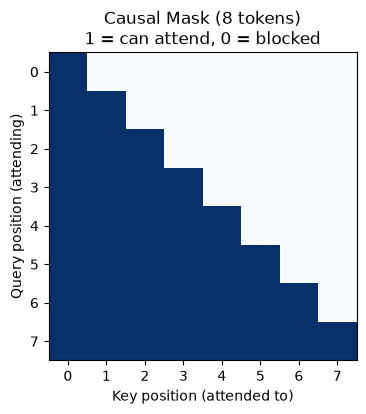

In [160]:
small = torch.tril(torch.ones(8, 8))
plt.figure(figsize=(4, 4))
plt.imshow(small, cmap="Blues")
plt.title("Causal Mask (8 tokens)\n1 = can attend, 0 = blocked")
plt.xlabel("Key position (attended to)")
plt.ylabel("Query position (attending)")
plt.xticks(range(8)); plt.yticks(range(8))
plt.show()

### Design choices
- **Pre-LayerNorm** (normalise *before* attention/FFN): trains more stably than the original post-LN Transformer.
- **GELU activation**: a smooth version of ReLU, used in GPT-2/3.
- **Weight tying**: the output layer reuses the token embedding matrix, which cuts parameters and usually improves results.
- **Small initial weights (std = 0.02)**: start predictions close to uniform, giving a stable start to training. This is confirmed by the initial loss of 4.70, close to ln(98) = 4.59.
- **Dropout (0.1)**: randomly zeroes activations during training to reduce overfitting.
- **Fused attention** (`F.scaled_dot_product_attention`): computes the same masked attention as the manual version, but without storing the full T×T attention matrix. This cut GPU memory use enough to stop it overflowing into system RAM, which made training ~7× faster (an epoch went from ~1,470 s to ~200 s).

## Task 5: Initialise the Model
- **Loss function:** cross-entropy, which measures how much probability the model gave to the correct next character
- **Optimiser:** AdamW, i.e. Adam with decoupled weight decay (the standard choice for Transformers)
- **Learning-rate schedule:** linear **warm-up**, then **cosine decay**
- **Gradient clipping** at 1.0, to prevent sudden huge updates
- **Mixed precision (bfloat16)** on the GPU, for faster training with lower memory use

In [161]:
EPOCHS        = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.1
WARMUP_STEPS  = 200
GRAD_CLIP     = 1.0

loss_fn = nn.CrossEntropyLoss()

In [162]:
def make_optimizer(model, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY):
    # Apply weight decay to weight matrices only, not to biases or LayerNorm parameters
    decay    = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=lr, betas=(0.9, 0.95),
    )

def make_scheduler(optimizer, total_steps, warmup_steps=WARMUP_STEPS):
    def lr_lambda(step):
        if step < warmup_steps:                       # linear warm-up
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress))   # cosine decay to 10%
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

In [163]:
torch.manual_seed(SEED)
config = ModelConfig()
model = TinyTransformer(config).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(config)
print(f"\nParameters: {n_params/1e6:.2f} M")
print(f"Steps per epoch: {len(train_loader):,}  |  Total steps: {EPOCHS * len(train_loader):,}")

ModelConfig(vocab_size=98, block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.1)

Parameters: 10.78 M
Steps per epoch: 1,093  |  Total steps: 5,465


## Task 6: Train the Model
Each training step:
1. **Forward pass:** feed a batch of input sequences into the Transformer and get the predicted next-token scores (logits)
2. **Loss:** cross-entropy between the predictions and the true next tokens
3. **Backpropagation:** `loss.backward()` computes the gradient of the loss for every parameter
4. **Update:** the optimiser adjusts the parameters to reduce the loss

After every epoch we measure the validation loss, and we keep the weights from the epoch with the **best validation loss**.

In [164]:
@torch.no_grad()
def evaluate(model, loader):
    """Average cross-entropy loss per token over a whole DataLoader."""
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            logits, _ = model(x)
            loss = loss_fn(logits.view(-1, logits.size(-1)), y.view(-1))
        total_loss += loss.item() * y.numel()
        total_tokens += y.numel()
    model.train()
    return total_loss / total_tokens

print(f"Validation loss before training: {evaluate(model, val_loader):.3f}")

Validation loss before training: 4.670


In [165]:
import time
import copy
from tqdm import tqdm

def train_model(model, epochs=EPOCHS, lr=LEARNING_RATE, verbose=True):
    optimizer = make_optimizer(model, lr)
    total_steps = epochs * len(train_loader)
    scheduler = make_scheduler(optimizer, total_steps)

    history = {"train_loss": [], "val_loss": [], "step_loss": [], "lr": [], "epoch_time": []}
    best_val, best_state = float("inf"), None

    model.train()
    for epoch in range(1, epochs + 1):
        start = time.time()
        epoch_loss, n_batches = 0.0, 0

        for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}", leave=False,
                         disable=not verbose):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

            # 1. Forward pass  +  2. Cross-entropy loss
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
                logits, _ = model(x)
                loss = loss_fn(logits.view(-1, logits.size(-1)), y.view(-1))

            # 3. Backpropagation
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)

            # 4. Parameter update
            optimizer.step()
            scheduler.step()

            epoch_loss += loss.item()
            n_batches += 1
            history["step_loss"].append(loss.item())
            history["lr"].append(scheduler.get_last_lr()[0])

        train_loss = epoch_loss / n_batches
        val_loss = evaluate(model, val_loader)
        elapsed = time.time() - start

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(elapsed)

        # Keep the best weights (checkpointing on validation loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(f"Epoch {epoch}/{epochs} | train loss {train_loss:.4f} | "
                  f"val loss {val_loss:.4f} | {elapsed:.0f}s")

    model.load_state_dict(best_state)
    if verbose:
        print(f"\nBest validation loss: {best_val:.4f}")
    return model, history

In [166]:
model, history = train_model(model, epochs=EPOCHS)

Epoch 1/5 | train loss 1.3812 | val loss 0.8482 | 155s


Epoch 2/5 | train loss 0.8066 | val loss 0.7298 | 190s


Epoch 3/5 | train loss 0.7206 | val loss 0.6797 | 205s


Epoch 4/5 | train loss 0.6693 | val loss 0.6509 | 202s


Epoch 5/5 | train loss 0.6372 | val loss 0.6373 | 208s

Best validation loss: 0.6373


## Task 7: Monitor Training

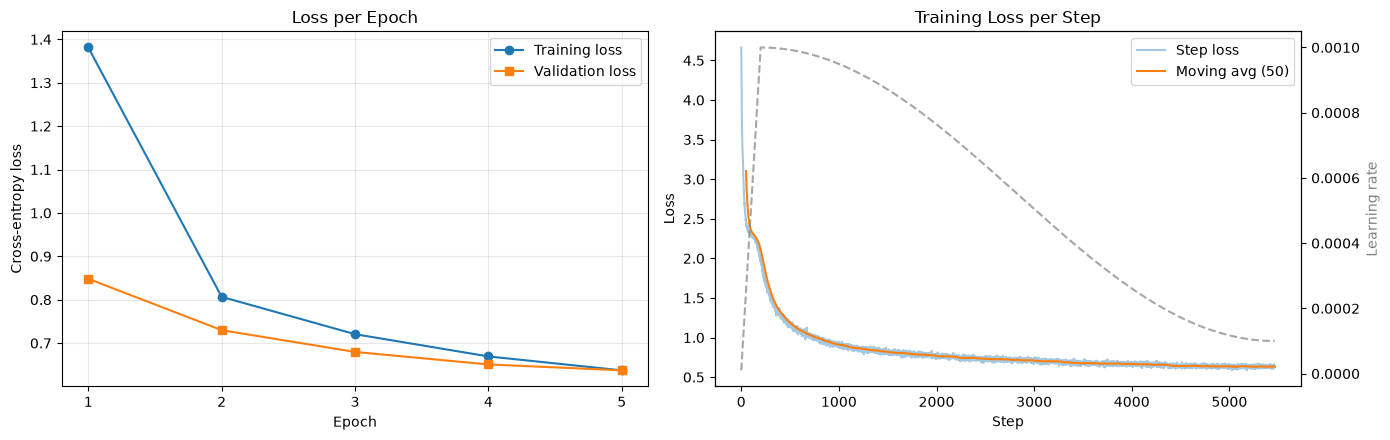

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Per-epoch train vs validation loss
epochs_range = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epochs_range, history["train_loss"], "o-", label="Training loss")
axes[0].plot(epochs_range, history["val_loss"], "s-", label="Validation loss")
axes[0].set_title("Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_xticks(list(epochs_range))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Per-step loss with the learning-rate schedule
ax2 = axes[1]
ax2.plot(history["step_loss"], alpha=0.4, label="Step loss")
window = 50
smoothed = np.convolve(history["step_loss"], np.ones(window) / window, mode="valid")
ax2.plot(range(window - 1, len(history["step_loss"])), smoothed, label=f"Moving avg ({window})")
ax2.set_title("Training Loss per Step")
ax2.set_xlabel("Step")
ax2.set_ylabel("Loss")
ax2.legend(loc="upper right")

ax_lr = ax2.twinx()
ax_lr.plot(history["lr"], color="gray", linestyle="--", alpha=0.7)
ax_lr.set_ylabel("Learning rate", color="gray")

plt.tight_layout()
plt.show()

### Observations
- Loss dropped quickly from **~4.7** (random guessing over 98 characters) to a validation loss of **0.848** after the first epoch, then improved more slowly.
- Final training loss: **0.637**, final validation loss: **0.637**.
- Training and validation loss stay close together, so the model is **not overfitting** (dropout and weight decay help here). Validation loss is even *lower* than training loss in early epochs, because dropout is switched off during validation and the training loss is averaged over the whole epoch, including its early, worse steps.
- The dashed line shows the learning rate: it warms up over the first 200 steps, then decays along a cosine curve.
- Total training time: about 16 minutes on an RTX 4050 Laptop GPU (5 epochs × ~190 s).

## Task 8: Evaluate the Model
**Perplexity** = e^(cross-entropy loss). It is the "effective number of choices" the model is uncertain between at each step: lower is better, and 1 would be perfect prediction.

To put the number in context, we compare against two simple baselines:
- **Uniform guessing**: every character equally likely (perplexity = vocabulary size)
- **Unigram model**: predict each character by how often it appears overall, ignoring context

In [169]:
import pandas as pd

val_loss = evaluate(model, val_loader)
val_ppl = math.exp(val_loss)

# Baseline 1: uniform
uniform_loss = math.log(vocab_size)

# Baseline 2: unigram (character frequencies from training data, +1 smoothing)
counts = torch.bincount(train_data, minlength=vocab_size).float() + 1
probs = counts / counts.sum()
unigram_loss = -torch.log(probs[val_data]).mean().item()

results = pd.DataFrame({
    "Model": ["Uniform guessing", "Unigram (char frequency)", "Tiny Transformer"],
    "Val loss": [uniform_loss, unigram_loss, val_loss],
    "Perplexity": [math.exp(uniform_loss), math.exp(unigram_loss), val_ppl],
    "Bits per char": [uniform_loss / math.log(2), unigram_loss / math.log(2), val_loss / math.log(2)],
})
results.round(3)

,Model,Val loss,Perplexity,Bits per char
0,Uniform guessing,4.585,98.000,6.615
1,Unigram (char frequency),3.056,21.240,4.409
2,Tiny Transformer,0.637,1.891,0.919


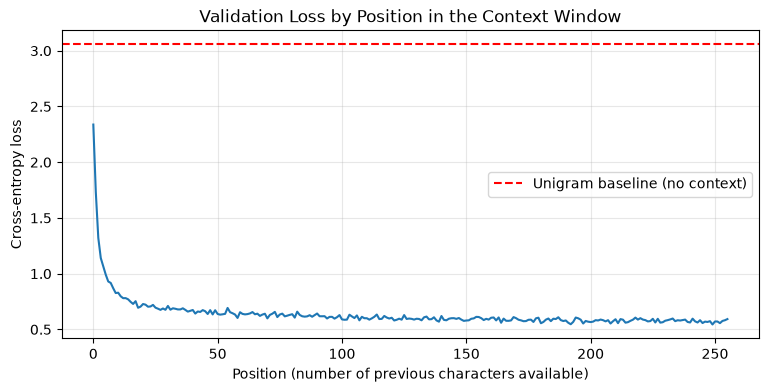

Loss at position 0:   2.338  (almost no context)
Loss at position 255: 0.593  (full context)


In [170]:
# Average loss at each position in the 256-character context window
@torch.no_grad()
def loss_by_position(model, loader):
    model.eval()
    total = torch.zeros(BLOCK_SIZE, device=device)
    n = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            logits, _ = model(x)
        loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), y.view(-1),
                               reduction="none").view(y.shape)
        total += loss.sum(dim=0)
        n += y.size(0)
    model.train()
    return (total / n).cpu().numpy()

pos_loss = loss_by_position(model, val_loader)

plt.figure(figsize=(9, 4))
plt.plot(pos_loss)
plt.axhline(unigram_loss, color="red", linestyle="--", label="Unigram baseline (no context)")
plt.title("Validation Loss by Position in the Context Window")
plt.xlabel("Position (number of previous characters available)")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Loss at position 0:   {pos_loss[0]:.3f}  (almost no context)")
print(f"Loss at position 255: {pos_loss[-1]:.3f}  (full context)")

### Observations
- Validation loss **0.637**, perplexity **1.89**, i.e. the model is choosing between fewer than 2 characters on average (0.92 bits per character).
- That is far better than uniform guessing (perplexity **98**) and the unigram baseline (perplexity **21.2**).
- Loss drops sharply as more context becomes available: from **2.34** at position 0 to **0.59** at full context. The model gains its predictive power from attention over previous characters.
- Even at position 0 (loss 2.34) the model beats the unigram baseline (3.06). Position 0 is not completely context-free: the model still sees **one** character and predicts the next, so it works like a *bigram* model (e.g. after `q` it can predict `u`, after `.` a space). One character of context is already better than none.

## Task 9: Generate Stories
Text is generated **autoregressively**, one character at a time:
1. Feed the prompt into the model
2. Take the scores (logits) for the **next** character and turn them into probabilities
3. **Sample** a character from that distribution and append it to the text
4. Repeat until `<EOS>` or the length limit

**Sampling controls:**
- **Temperature** scales the logits before softmax. Below 1, outputs are safer and more repetitive; above 1, they're more random and creative.
- **Top-k** samples only from the *k* most likely characters, which avoids rare nonsense picks.

In [171]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=600, temperature=0.8, top_k=None, stop_at_eos=True):
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.cfg.block_size:]
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            logits, _ = model(idx_cond)
        logits = logits[:, -1, :].float()

        if temperature == 0:
            next_id = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)

        if stop_at_eos and next_id.item() == eos_id:
            break
        idx = torch.cat([idx, next_id], dim=1)

    model.train()
    return decode(idx[0].tolist())

In [172]:
torch.manual_seed(SEED)
print(generate(model, "Once upon a time", temperature=0.8, top_k=20))

Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine and explore. One day, she saw a wise owl near the house. She wanted to cry and asked her mom what was wrong.

"Mom, can I have the wise owl of the wise owl, please?" her mom asked.

"Sure, it will be better to try the wise owl. Let's put it back together," said her mom.

As they were playing, they noticed that the wise owl was holding the wise owl and they all came to Lily's house. "Lily, stop it!" Mom said.

"You're welcome, my diary. It was beautiful," Lily said.

"Yes, thank you," Mom said. "But first, let's do 


In [173]:
prompts = [
    "Once upon a time, there was a little dog named",
    "Lily wanted to go to the park, but",
    "The big red ball",
    "One day, Tom found a magic",
]

torch.manual_seed(SEED)
for p in prompts:
    print("=" * 80)
    print(f"PROMPT: {p!r}\n")
    print(generate(model, p, temperature=0.8, top_k=20))
    print()

PROMPT: 'Once upon a time, there was a little dog named'

Once upon a time, there was a little dog named Spot. Spot was a patch near the pond. He would fly high in the sky and sing his flute.

One day, Spot found a big box of cool cookies. He was very hungry and asked his mom what it was and she told him that they were doing and helping each other.

The little boy was so happy to help the cookies and practiced them out while that night. He dreamed of all this cool cookies and the adventures he learned and he wouldn't like it too.

PROMPT: 'Lily wanted to go to the park, but'

Lily wanted to go to the park, but her mommy said no. Lily was sad and didn't know what to do. She learned that sometimes things be wrong, it's important to the park and that they can be polite too.

Lily and her mommy worked together to teach the story about a fairy and a friend. They were all very polite to each other and got the message. They were happy to be able to pick up the fairy and dance together.

PROMP

In [174]:
prompt = "Once upon a time, there was a girl named Sue."

for temp in [0, 0.5, 1.0, 1.5]:
    torch.manual_seed(SEED)
    print("=" * 80)
    label = "greedy" if temp == 0 else f"temperature {temp}"
    print(f"{label.upper()}\n")
    print(generate(model, prompt, temperature=temp, max_new_tokens=300))
    print()

GREEDY

Once upon a time, there was a girl named Sue. Sue loved to play outside in the grass. One day, she saw a big box in the grass. Sue wanted to play with the box but she didn't know how. She tried to pull the box but it was too heavy.

Sue was sad because she couldn't play with the box. She wanted to play with the box but she couldn't find it. Sh

TEMPERATURE 0.5

Once upon a time, there was a girl named Sue. Sue loved to play with her toys and her favorite toy toy was a pretty dress. One day, Sue wanted to make a pretty dress with her mom.

Sue wanted to make a pretty dress with her favorite doll, but she didn't know how. So, she went to the kitchen and started to make a pretty dress. Sue saw a big bow

TEMPERATURE 1.0

Once upon a time, there was a girl named Sue. She loved to paint more pictures, but one day she went outside and asked her mommy to have a picnic. Her mommy was so excited. Together, they packed a big toy car to paint a letter which meant letters that they wouldn'

### Observations
- The model produces **mostly correct English spelling and grammar**, even though it only ever saw individual characters. It learned words, punctuation, dialogue in quotation marks and paragraph breaks from scratch.
- Stories follow the TinyStories pattern: a named character (Lily, Spot, Tim, Sue), a simple problem, dialogue and a resolution, sometimes with a moral (*"it's important to … be polite"*).
- **Weaknesses:**
  - **Repetition:** *"the wise owl of the wise owl"*, *"the wise owl was holding the wise owl"*
  - **Logic errors:** Lily *"wanted to cry"* and then asked her mom *"what was wrong"*; *"sang his foot"*; Tim *"was a happy time"*
  - **Plot drift:** with only a 256-character context window, the model cannot remember the start of a long story, so the plot wanders.
- **Temperature:**
  - **Greedy (0)** is grammatical but repetitive (*"wanted to play with the box"* three times).
  - **0.5** is safe and simple.
  - **1.0** is more varied and creative.
  - **1.5** breaks down into misspellings (*"tryed"*, *"playingle"*, *"chizzing"*) and even the encoding-error character `™` from the dataset.
  - **0.5–0.8 gives the best balance.**

## Task 10: Experiment with Model Settings
We change one setting at a time and compare against a baseline (6 layers, 6 heads).
- **Layers and heads:** each model is trained for 2 epochs with identical settings otherwise, so the comparison is fair.
- **Epochs:** taken from the main 5-epoch training run.

In [175]:
exp_results = []
exp_histories = {}

def run_experiment(name, epochs=2, **changes):
    """Train a fresh model with some config changes and record the results."""
    print(f"\n{'=' * 70}\n{name}\n{'=' * 70}")
    torch.manual_seed(SEED)
    cfg = ModelConfig(**changes)
    m = TinyTransformer(cfg).to(device)
    n_params = sum(p.numel() for p in m.parameters())

    m, hist = train_model(m, epochs=epochs)

    torch.manual_seed(SEED)
    sample = generate(m, "Once upon a time", max_new_tokens=300, temperature=0.8, top_k=20)

    exp_results.append({
        "Experiment": name,
        "Layers": cfg.n_layer,
        "Heads": cfg.n_head,
        "Params (M)": n_params / 1e6,
        "Epochs": epochs,
        "Train loss": hist["train_loss"][-1],
        "Val loss": min(hist["val_loss"]),
        "Perplexity": math.exp(min(hist["val_loss"])),
        "Time (s)": sum(hist["epoch_time"]),
        "Sample": sample,
    })
    exp_histories[name] = hist

    del m
    torch.cuda.empty_cache()
    print(f"\nSample:\n{sample}")

In [176]:
run_experiment("Baseline (6 layers, 6 heads)", n_layer=6, n_head=6)


Baseline (6 layers, 6 heads)


Epoch 1/2 | train loss 1.3819 | val loss 0.8381 | 210s


Epoch 2/2 | train loss 0.7885 | val loss 0.7184 | 193s

Best validation loss: 0.7184

Sample:
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine and explore. One day, she saw a wise old man playing on the swings. He wanted to swing and swing in the sandwiches. She swingt the man and looked in the sand. 

Lily was so happy and proud of herself. She tried to spray 


In [177]:
run_experiment("2 layers", n_layer=2)


2 layers


Epoch 1/2 | train loss 1.4571 | val loss 0.9272 | 65s


Epoch 2/2 | train loss 0.9214 | val loss 0.8268 | 65s

Best validation loss: 0.8268

Sample:
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine and she would be nice and she was the forest. One day, she went to the park to play outside and saw a big hat and had made a tiny colourful of their faces. She said, "Grandma, I understand?"

Lily asked, "Of course, Lily


In [178]:
run_experiment("4 layers", n_layer=4)


4 layers


Epoch 1/2 | train loss 1.3980 | val loss 0.8582 | 121s


Epoch 2/2 | train loss 0.8215 | val loss 0.7419 | 122s

Best validation loss: 0.7419

Sample:
Once upon a time, there was a little girl named Lily. She loved to play outside in the sun, envillage what she found. One day, the little girl hopped into the distance. She was so proud of herself for a while.

As she walked home, she noticed her owner starting to see what was on a big, soft captain. She tried to t


In [179]:
run_experiment("1 head", n_head=1)


1 head


Epoch 1/2 | train loss 1.4474 | val loss 0.8787 | 201s


Epoch 2/2 | train loss 0.8497 | val loss 0.7491 | 202s

Best validation loss: 0.7491

Sample:
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine and explore. One day, she saw a wise other owl. They decided to go outside to the window. She put on the wall and looked for their mom.

The kitty was oxygen the store and looked around, but she saw a little boy who want


In [180]:
run_experiment("3 heads", n_head=3)


3 heads


Epoch 1/2 | train loss 1.3871 | val loss 0.8475 | 177s


Epoch 2/2 | train loss 0.8062 | val loss 0.7267 | 175s

Best validation loss: 0.7267

Sample:
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine and she also liked to play outside in the sunshine. One day, she was playing outside when she saw a big storm on the ground. It was a big, board sinkle, but it said no. Inside the storm, there was a pretty board who want


### Results

In [181]:
exp_df = pd.DataFrame(exp_results).drop(columns="Sample")
exp_df.round(3)

,Experiment,Layers,Heads,Params (M),Epochs,Train loss,Val loss,Perplexity,Time (s)
0,"Baseline (6 layers, 6 heads)",6,6,10.783,2,0.788,0.718,2.051,402.895
1,2 layers,2,6,3.686,2,0.921,0.827,2.286,129.068
2,4 layers,4,6,7.235,2,0.822,0.742,2.100,242.395
3,1 head,6,1,10.783,2,0.850,0.749,2.115,402.124
4,3 heads,6,3,10.783,2,0.806,0.727,2.068,351.675


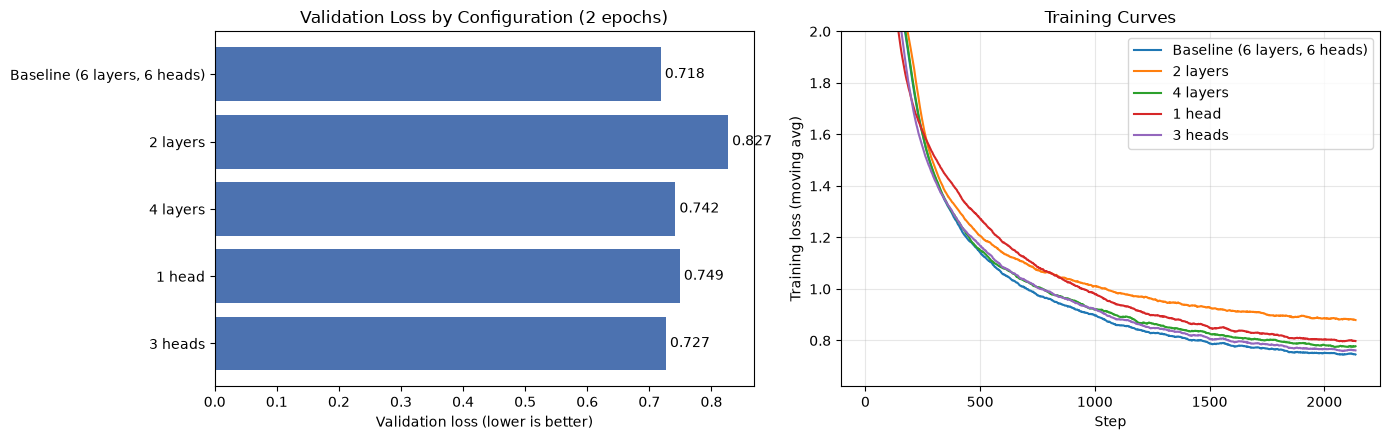

In [182]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Validation loss per experiment
axes[0].barh(exp_df["Experiment"], exp_df["Val loss"], color="#4c72b0")
axes[0].set_xlabel("Validation loss (lower is better)")
axes[0].set_title("Validation Loss by Configuration (2 epochs)")
axes[0].invert_yaxis()
for i, v in enumerate(exp_df["Val loss"]):
    axes[0].text(v, i, f" {v:.3f}", va="center")

# Smoothed training curves
window = 50
for name, hist in exp_histories.items():
    smoothed = np.convolve(hist["step_loss"], np.ones(window) / window, mode="valid")
    axes[1].plot(smoothed, label=name)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Training loss (moving avg)")
axes[1].set_title("Training Curves")
axes[1].set_ylim(top=2.0)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Epoch,Train loss,Val loss,Perplexity
0,1,1.3812,0.8482,2.3355
1,2,0.8066,0.7298,2.0747
2,3,0.7206,0.6797,1.9732
3,4,0.6693,0.6509,1.9172
4,5,0.6372,0.6373,1.8914


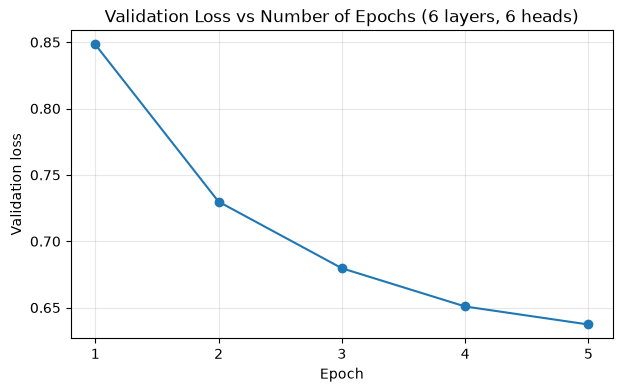

In [183]:
epoch_df = pd.DataFrame({
    "Epoch": range(1, len(history["val_loss"]) + 1),
    "Train loss": history["train_loss"],
    "Val loss": history["val_loss"],
    "Perplexity": [math.exp(v) for v in history["val_loss"]],
})
display(epoch_df.round(4))

plt.figure(figsize=(7, 4))
plt.plot(epoch_df["Epoch"], epoch_df["Val loss"], "o-")
plt.title("Validation Loss vs Number of Epochs (6 layers, 6 heads)")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.xticks(epoch_df["Epoch"])
plt.grid(alpha=0.3)
plt.show()

### Observations
**Layers** (all 6 heads, 2 epochs)

| Layers | Params | Val loss | Time |
|---|---|---|---|
| 2 | 3.7 M | 0.827 | 135 s |
| 4 | 7.2 M | 0.742 | 260 s |
| 6 | 10.8 M | **0.718** | 343 s |

- More layers → lower loss. Going from 2 to 4 layers helped much more (−0.085) than 4 to 6 (−0.024): diminishing returns.
- Deeper models can combine patterns in more steps (letters → words → phrases), so their text is more fluent. The 2-layer model produces broken phrases such as *"she was the forest"* and *"a tiny colourful of their faces"*.
- The cost: more parameters and longer training time (2.5× slower for 6 layers vs 2).

**Attention heads** (all 6 layers, 2 epochs)

| Heads | Head size | Val loss | Time |
|---|---|---|---|
| 1 | 384 | 0.749 | 443 s |
| 3 | 128 | 0.728 | 414 s |
| 6 | 64 | **0.718** | 343 s |

- Changing the number of heads does **not** change the parameter count (10.78 M in all cases). It only changes how the 384 dimensions are split.
- More heads gave lower loss: multiple heads let the model attend to several things at once (e.g. the previous letter *and* the start of the word), while a single head must average everything into one attention pattern.
- 1 head was also the **slowest**. A single head is 384 dimensions wide, which is likely larger than the fastest attention kernel (FlashAttention, up to 256 dimensions per head) supports, so PyTorch falls back to a slower kernel. The GPU kernels in general run best with small heads, which also fits 3 heads (128 dims) being slower than 6 heads (64 dims).

**Epochs** (6 layers, 6 heads)
- Validation loss kept falling from epoch 1 to epoch 5 (**0.848 → 0.730 → 0.680 → 0.651 → 0.637**), but the improvement shrank each epoch (−0.118, −0.050, −0.029, −0.014): diminishing returns.
- The 5-epoch model writes more coherent stories than the same architecture after 2 epochs.
- Since validation loss never went up, the model did not overfit. More epochs or more data would probably improve it further.
- Interesting detail: the 2-epoch baseline reached **0.718** at epoch 2, better than the 5-epoch run at its epoch 2 (**0.730**). The 2-epoch run's learning rate had already decayed to its minimum, so it made smaller, more precise updates. This shows the **learning-rate schedule** affects results, not just the number of epochs.

**Note on timings:** each setting was trained only once on a laptop GPU, where speed varies with temperature and background programs. The time differences show the general trend, not exact costs.

## Task 11: Save the Trained Model
To generate text later without retraining, three things are saved together in `models/tiny_transformer.pt`:
1. **Model weights** (`state_dict`): the learned parameters
2. **Configuration**: layers, heads, embedding size and block size, needed to rebuild the same architecture
3. **Vocabulary** (`itos`): the character ↔ id mapping, without which the model's outputs cannot be decoded

The training history is saved too, so the loss curves can be redrawn. We then reload everything into a **brand-new model** and check that it gives the same validation loss.

In [ ]:
from pathlib import Path

# The notebook runs from the notebooks/ folder; save into the project's models/ folder
MODEL_DIR = Path("../models") if Path.cwd().name == "notebooks" else Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "tiny_transformer.pt"

checkpoint = {
    "model_state": model.state_dict(),
    "config": asdict(config),
    "itos": itos,
    "history": history,
}
torch.save(checkpoint, MODEL_PATH)
print(f"Saved to {MODEL_PATH.resolve()}  ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

# Check: reload into a fresh model and compare validation loss
ckpt = torch.load(MODEL_PATH, map_location=device)
reloaded = TinyTransformer(ModelConfig(**ckpt["config"])).to(device)
reloaded.load_state_dict(ckpt["model_state"])
print(f"Validation loss - trained model:  {evaluate(model, val_loader):.4f}")
print(f"Validation loss - reloaded model: {evaluate(reloaded, val_loader):.4f}")

del reloaded, ckpt
torch.cuda.empty_cache()

Saved to C:\Users\Ravindu\Developing-a-Tiny-Transformer-Language-Model\models\tiny_transformer.pt  (43.3 MB)
Validation loss - trained model:  0.6373
Validation loss - reloaded model: 0.6373


## Discussion: Mechanisms Used to Improve Performance
The mechanisms below are grouped by where they act. Where possible, the evidence comes from this notebook's own results.

### Architecture
| Mechanism | What it does | Evidence in this notebook |
|---|---|---|
| **Masked multi-head self-attention** | Each token gathers information from earlier tokens; several heads attend to different patterns at once | Loss falls from **2.34** (1 character of context) to **0.59** (full context). 6 heads (0.718) beat 1 head (0.749) with the same parameter count |
| **Depth (stacked blocks)** | Each layer builds on the last: letters → words → phrases | 2 → 4 → 6 layers: **0.827 → 0.742 → 0.718** validation loss |
| **Scaled dot-product (÷√d)** | Stops attention scores from growing so large that softmax saturates and gradients vanish | Standard; required for stable training |
| **Positional embeddings** | Give the model word order, which attention alone does not have | Without them, "dog bites man" = "man bites dog" |
| **Residual connections** | `x + f(x)` gives gradients a direct path through the network, so deep models train stably | Loss fell in every epoch of every 6-layer run |
| **Pre-LayerNorm** | Normalises activations *before* each sub-layer, keeping their scale stable | Used in GPT-2 and later; more stable than the original post-LN design |
| **Feed-forward network (4× width, GELU)** | Processes each position after attention has mixed information | About two-thirds of each block's parameters |
| **Weight tying** | The output layer reuses the token-embedding matrix | Fewer parameters; usually better generalisation |
| **Small initialisation (std 0.02)** | Starts predictions close to uniform | Initial loss **4.70** ≈ ln(98) = **4.59**, a clean starting point |

### Training
| Mechanism | What it does | Evidence in this notebook |
|---|---|---|
| **AdamW optimiser** | Adaptive per-parameter learning rates, with weight decay applied separately | Standard for Transformers |
| **Weight decay (0.1)** | Keeps weights small, which reduces overfitting (not applied to biases or LayerNorm) | Train and validation loss stayed equal (**0.637** vs **0.637**) |
| **Dropout (0.1)** | Randomly switches off activations during training | Same as above: no overfitting |
| **Learning-rate warm-up** | Starts with small updates for 200 steps while the weights are still random | Visible as the rising start of the learning-rate curve in Task 7 |
| **Cosine learning-rate decay** | Large steps early, small precise steps at the end | The 2-epoch run (LR fully decayed) reached **0.718** at epoch 2, while the 5-epoch run had **0.730** at its epoch 2 |
| **Gradient clipping (1.0)** | Caps the size of each update, preventing sudden jumps | Standard safeguard for Transformer training |
| **Best-checkpoint selection** | Keeps the weights from the epoch with the lowest validation loss | Guards against late overfitting |
| **More training epochs** | More passes over the data | **0.848 → 0.637** over 5 epochs, with diminishing returns |

### Efficiency
| Mechanism | What it does | Evidence in this notebook |
|---|---|---|
| **Fused attention** (`scaled_dot_product_attention`) | Same maths, without storing the full T×T attention matrix | Stopped GPU memory overflowing into system RAM: an epoch went from **~1,470 s to ~190 s** (~7× faster) |
| **Mixed precision (bfloat16)** | Runs most computation in 16-bit on the GPU | Faster training and lower memory use |

### Data and generation
| Mechanism | What it does | Evidence in this notebook |
|---|---|---|
| **`<EOS>` token** | Marks the end of each story | The model can finish a story and stop |
| **Temperature** | Controls how random sampling is | Greedy repeats itself; **0.5–0.8** is best; **1.5** gives misspellings like *"tryed"*, *"playingle"* |
| **Top-k sampling** | Samples only from the *k* most likely characters | Prevents rare, nonsense characters |

### What would improve it further
- **More data and more epochs:** validation loss was still falling at epoch 5, and only 20,000 of ~2.1 million stories were used.
- **A longer context window:** at 256 characters the model forgets the start of a story, which causes the plot drift seen in Task 9.
- **A sub-word (BPE) tokenizer:** each token would cover several characters, so the same context window would hold more text, and the model would not have to learn spelling.
- **Larger models:** the layer experiments show that capacity still helps.

## Conclusion
- We built a GPT-style, decoder-only Transformer **from scratch** in PyTorch (10.8 M parameters, 6 layers, 6 heads, 256-character context) and trained it on 20,000 TinyStories with character-level tokenisation.
- After 5 epochs (~16 minutes on an RTX 4050 Laptop GPU) it reached a validation loss of **0.637** (perplexity **1.89**, 0.92 bits per character), far better than the uniform (perplexity 98) and unigram (21.2) baselines, with no sign of overfitting.
- The model learned spelling, grammar, punctuation, dialogue and the typical TinyStories structure purely from characters. Its stories still repeat themselves, contain logic errors and drift off-topic, mainly because of the short 256-character context and the small model.
- Experiments showed that **more layers** and **more attention heads** both lower the loss, with diminishing returns, and that **more epochs** kept improving the model. The learning-rate schedule also mattered.
- **Possible improvements:** train on more stories and for more epochs, use a longer context window, and switch to a sub-word (BPE) tokenizer so the model sees more text per context window and does not have to learn spelling.

In [184]:
model.cfg

ModelConfig(vocab_size=98, block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.1)